# Assignment No. 4: Machine Learning Model Application & Evaluation
**Course:** Introduction to Data Science  
**Title:** Apply and Compare Machine Learning Models on a Real-World Dataset

**Dataset:** Breast Cancer Wisconsin (Diagnostic) dataset  
**Task type:** Binary Classification

## 1. Define the Problem
**Dataset.** The Breast Cancer Wisconsin (Diagnostic) dataset (UCI repository, bundled with scikit-learn) has 569 patient samples. Each sample is described by 30 numeric features computed from a digitized image of a fine needle aspirate (FNA) of a breast mass. The features describe the cell nuclei: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and fractal dimension. For each of these, the mean, standard error and "worst" (largest) value are recorded.

**Problem.** Predict whether a tumour is **malignant** (cancerous) or **benign** (non-cancerous) from these measurements.

- **Features (X):** the 30 numeric cell-nucleus measurements
- **Target (y):** diagnosis, where `1 = Malignant` and `0 = Benign`
- **Problem type:** **Classification** (the target is a category, not a continuous number)

I deliberately set **Malignant = 1** as the *positive class*, because it is the case we care most about detecting. This matters for Precision and Recall below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report, ConfusionMatrixDisplay)

import warnings; warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

# In scikit-learn: 0 = malignant, 1 = benign. Flip so that Malignant = 1 (our positive class).
df["target"] = (df["target"] == 0).astype(int)

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("\nClass distribution (1 = Malignant, 0 = Benign):")
print(df["target"].value_counts())
print((df["target"].value_counts(normalize=True)*100).round(1).astype(str) + " %")
df.head()

Shape: (569, 31)
Missing values: 0

Class distribution (1 = Malignant, 0 = Benign):
target
0    357
1    212
Name: count, dtype: int64
target
0    62.7 %
1    37.3 %
Name: proportion, dtype: str


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


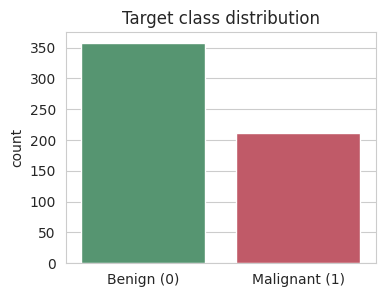

In [3]:
plt.figure(figsize=(4,3))
sns.countplot(x="target", data=df, palette=["#4C9F70", "#D1495B"])
plt.xticks([0,1], ["Benign (0)", "Malignant (1)"])
plt.title("Target class distribution"); plt.xlabel(""); plt.show()

**Observation:** There are no missing values. The classes are moderately imbalanced (about 63% benign, 37% malignant), so Accuracy alone can be misleading. This is why Precision, Recall and F1 are also needed.

## 2. Train-Test Split

In [4]:
X = df.drop(columns="target")
y = df["target"]

# 80/20 split; stratify keeps the same benign/malignant ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("Malignant share  train: %.1f%%  test: %.1f%%" % (y_train.mean()*100, y_test.mean()*100))

Training set: (455, 30) | Test set: (114, 30)
Malignant share  train: 37.4%  test: 36.8%


All models are **trained only on the training set** and evaluated on the **unseen test set**. Feature scaling (`StandardScaler`) is needed for Logistic Regression and KNN, which are sensitive to feature scale. To avoid data leakage, the scaler is placed inside a `Pipeline`, so it is fitted on training data only. Decision Tree and Random Forest do not need scaling.

## 3. Apply Suitable Models

In [5]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train, y_train)          # training data only
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: KNN
Trained: Decision Tree


Trained: Random Forest


## 4. Evaluate the Models
For each model we compute the Confusion Matrix, Accuracy, Precision, Recall and F1-Score on the **test set**. With Malignant as the positive class:

| | Predicted Benign | Predicted Malignant |
|---|---|---|
| **Actual Benign** | TN | FP (false alarm) |
| **Actual Malignant** | **FN (missed cancer)** | TP |

In [6]:
results, cms = [], {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    cms[name] = cm
    tn, fp, fn, tp = cm.ravel()
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
        "FN (missed cancers)": fn,
        "FP (false alarms)":   fp,
    })
    print("="*60); print(name); print("="*60)
    print("Confusion matrix [[TN FP] [FN TP]]:\n", cm)
    print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"], digits=3))

Logistic Regression
Confusion matrix [[TN FP] [FN TP]]:
 [[71  1]
 [ 3 39]]
              precision    recall  f1-score   support

      Benign      0.959     0.986     0.973        72
   Malignant      0.975     0.929     0.951        42

    accuracy                          0.965       114
   macro avg      0.967     0.957     0.962       114
weighted avg      0.965     0.965     0.965       114

KNN
Confusion matrix [[TN FP] [FN TP]]:
 [[71  1]
 [ 4 38]]
              precision    recall  f1-score   support

      Benign      0.947     0.986     0.966        72
   Malignant      0.974     0.905     0.938        42

    accuracy                          0.956       114
   macro avg      0.961     0.945     0.952       114
weighted avg      0.957     0.956     0.956       114

Decision Tree
Confusion matrix [[TN FP] [FN TP]]:
 [[68  4]
 [ 4 38]]
              precision    recall  f1-score   support

      Benign      0.944     0.944     0.944        72
   Malignant      0.905     0.9

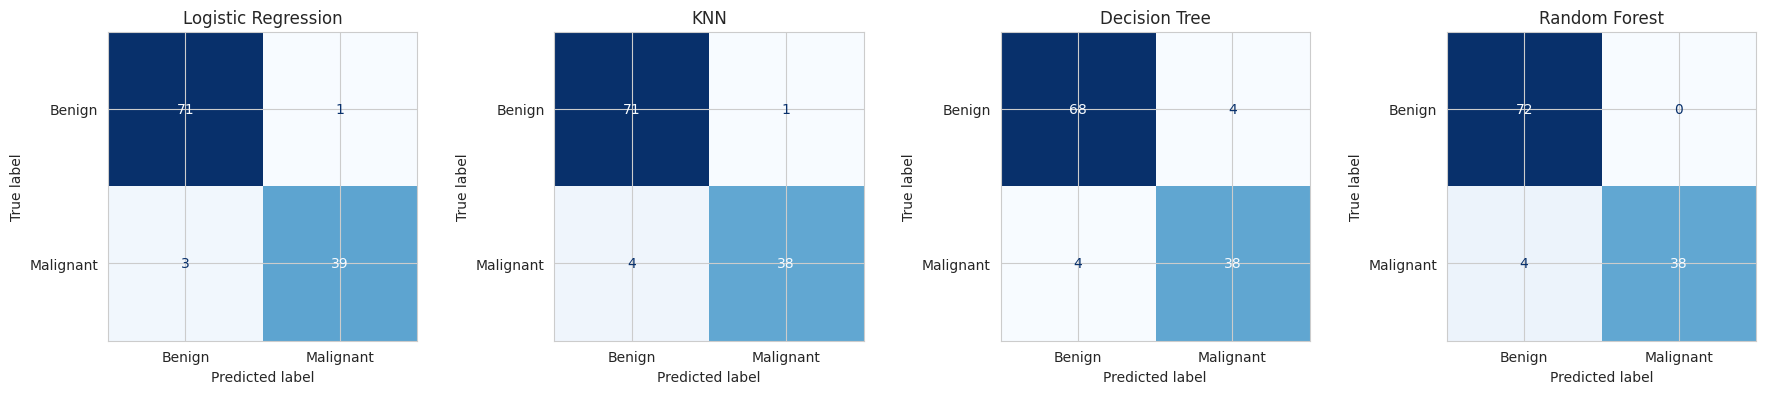

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, cm) in zip(axes, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 5. Compare the Models

,Accuracy,Precision,Recall,F1,FN (missed cancers),FP (false alarms)
Model,,,,,,
Logistic Regression,0.9649,0.9750,0.9286,0.9512,3,1
KNN,0.9561,0.9744,0.9048,0.9383,4,1
Decision Tree,0.9298,0.9048,0.9048,0.9048,4,4
Random Forest,0.9649,1.0000,0.9048,0.9500,4,0


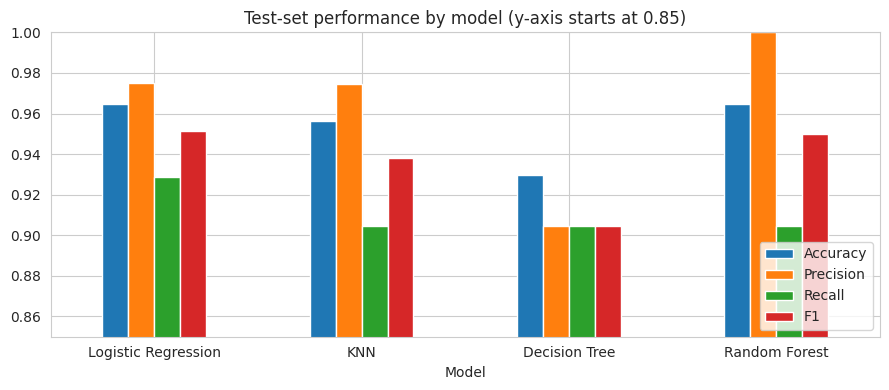

In [8]:
comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(4))

ax = comparison[["Accuracy","Precision","Recall","F1"]].plot(kind="bar", figsize=(9,4), ylim=(0.85,1.0), rot=0)
ax.set_title("Test-set performance by model (y-axis starts at 0.85)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### Checking for Overfitting / Underfitting

In [9]:
# Compare training accuracy vs test accuracy, and use 5-fold cross-validation on the training set
# to see how stable each model is across different data subsets.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc  = accuracy_score(y_test,  model.predict(X_test))
    cv_rec = cross_val_score(model, X_train, y_train, cv=cv, scoring="recall")
    cv_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    rows.append({"Model": name, "Train Acc": train_acc, "Test Acc": test_acc,
                 "Gap (Train-Test)": train_acc - test_acc,
                 "CV Acc (mean)": cv_acc.mean(), "CV Recall (mean)": cv_rec.mean(), "CV Recall (std)": cv_rec.std()})
fit_check = pd.DataFrame(rows).set_index("Model")
display(fit_check.round(4))

,Train Acc,Test Acc,Gap (Train-Test),CV Acc (mean),CV Recall (mean),CV Recall (std)
Model,,,,,,
Logistic Regression,0.9868,0.9649,0.0219,0.9736,0.9529,0.0399
KNN,0.9780,0.9561,0.0219,0.9648,0.9176,0.0343
Decision Tree,1.0000,0.9298,0.0702,0.9231,0.8941,0.0606
Random Forest,1.0000,0.9649,0.0351,0.9626,0.9353,0.0390


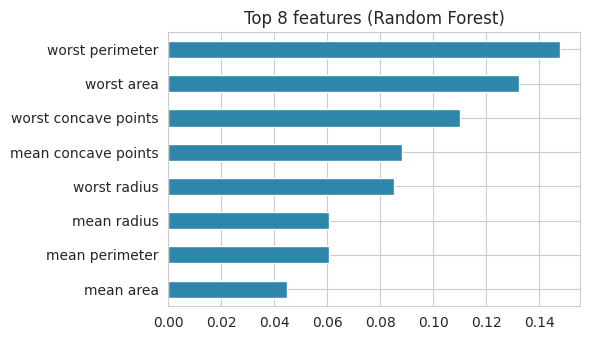

In [10]:
# Which features matter most? (Random Forest)
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
imp[::-1].plot(kind="barh", figsize=(6,3.5), color="#2E86AB")
plt.title("Top 8 features (Random Forest)"); plt.tight_layout(); plt.show()

## 6. Final Conclusion

**Which model performed best?**  
**Logistic Regression** performed best for this problem. It has the highest Recall (0.929), the highest F1-score (0.951) and ties for the highest Accuracy (0.965) on the unseen test set. It also missed the fewest cancers (3 false negatives, versus 4 for each of the other models).

**Which metric was mainly used to make this decision?**  
**Recall** (supported by F1 and the number of false negatives in the confusion matrix). Accuracy was not used as the deciding factor. Logistic Regression and Random Forest have identical Accuracy (0.965), yet they make different kinds of mistakes. Random Forest has perfect Precision (1.000) but misses 4 malignant tumours, while Logistic Regression misses 3 and raises 1 false alarm.

**Why is that metric important for this problem?**  
Here the positive class is *malignant*. A **false negative** means a cancerous tumour is labelled benign, so the patient may go untreated and the disease can progress. A **false positive** only means a benign tumour is flagged, which leads to a follow-up test or biopsy. The cost of a missed cancer is far higher than the cost of a false alarm, so a model should catch as many malignant cases as possible. That is exactly what Recall measures. F1 was used as a secondary check so that a model could not get a good Recall simply by flagging everything as malignant.

**Is there any sign of overfitting or underfitting?**
- **Decision Tree: clear overfitting.** It scores 100% on the training data but only 92.98% on the test set (gap of 7.0 points), and it has the lowest cross-validation accuracy (0.923) and Recall (0.894) with the highest variance. It memorised the training data instead of learning general patterns.
- **Random Forest: mild overfitting.** It also reaches 100% training accuracy, with a 3.5-point train-test gap. This is typical for forests and its test performance is still strong, but its Recall is lower than Logistic Regression.
- **Logistic Regression and KNN: well fitted.** The train-test gap is small (about 2.2 points) and the cross-validation scores are close to the test scores. There is no sign of underfitting, since all models reach above 93% accuracy. This suggests the classes are almost linearly separable in this feature space.

**Limitations.** The test set is small (114 samples, 42 malignant), so one extra correct or incorrect prediction changes Recall by about 2.4 percentage points. The differences between Logistic Regression, KNN and Random Forest are therefore small. The 5-fold cross-validation Recall (Logistic Regression 0.953, Random Forest 0.935, KNN 0.918, Decision Tree 0.894) points the same way and supports the choice. In a real clinical setting, the decision threshold could also be lowered to push Recall even higher, and results should be confirmed on more data.

**Final answer:** Logistic Regression is the recommended model because it gives the best Recall and F1 with the fewest missed cancers and no meaningful overfitting. The Decision Tree is the weakest and overfits.
